# Analyzing Income Distribution and Household Demographics

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy

#### Reading csv file to make DataFrame

In [82]:
Data = pd.read_csv("household_dataset.csv")
Data

,Household_ID,Age_of_Household_Head,Household_Income,Education_Level,Family_Size,Owns_House,Urban_Rural
0,HH0001,62,17000,Primary,4,Yes,Rural
1,HH0002,65,65500,Graduate,2,No,Urban
2,HH0003,27,31500,Secondary,1,No,Rural
3,HH0004,66,44500,Graduate,8,No,Rural
4,HH0005,22,40500,Graduate,7,Yes,Urban
...,...,...,...,...,...,...,...
495,HH0496,70,40000,Secondary,2,Yes,Urban
496,HH0497,38,17000,Secondary,7,Yes,Rural
497,HH0498,54,58000,Graduate,7,Yes,Urban
498,HH0499,61,17500,Secondary,5,Yes,Rural


In [83]:
Data.shape

(500, 7)

In [84]:
Data.head()

,Household_ID,Age_of_Household_Head,Household_Income,Education_Level,Family_Size,Owns_House,Urban_Rural
0,HH0001,62,17000,Primary,4,Yes,Rural
1,HH0002,65,65500,Graduate,2,No,Urban
2,HH0003,27,31500,Secondary,1,No,Rural
3,HH0004,66,44500,Graduate,8,No,Rural
4,HH0005,22,40500,Graduate,7,Yes,Urban


In [85]:
Data.tail()

,Household_ID,Age_of_Household_Head,Household_Income,Education_Level,Family_Size,Owns_House,Urban_Rural
495,HH0496,70,40000,Secondary,2,Yes,Urban
496,HH0497,38,17000,Secondary,7,Yes,Rural
497,HH0498,54,58000,Graduate,7,Yes,Urban
498,HH0499,61,17500,Secondary,5,Yes,Rural
499,HH0500,31,55500,Graduate,2,Yes,Urban


## Part-A : Theory & Definations

In [86]:
Data.dtypes

Household_ID             object
Age_of_Household_Head     int64
Household_Income          int64
Education_Level          object
Family_Size               int64
Owns_House               object
Urban_Rural              object
dtype: object

#### Numerical Data

##### Measurable quantities. Examples from dataset: Age_of_Household_head,Household_Income,Family_Size

##### listing Numerical-Columns

In [87]:
Numerical_Columns = ["Age_of_Household_Head","Household_Income","Family_Size"]
print(f"Numeric-Columns : {Numerical_Columns}")

Numeric-Columns : ['Age_of_Household_Head', 'Household_Income', 'Family_Size']


#### categorical Data

##### Labels/Groups with no mathematical meaning. Examples from dataset : Household_Id,Education_Level,Owns_House,Urban_Rural

In [88]:
Categorical_Columns = ["Household_ID","Education_Level","Owns_House","Urban_Rural"]
print(f"Category-Columns : {Categorical_Columns}")

Category-Columns : ['Household_ID', 'Education_Level', 'Owns_House', 'Urban_Rural']


#### Descriptive & Inferential Statistics

##### Descriptive : Summarises and describes features of the dataset — mean, median, mode, standard deviation, skewness etc.
##### Inferential : Uses sample data to make predictions or draw conclusions about a larger population — hypothesis tests, confidence intervals.

In [89]:
Data.describe()

,Age_of_Household_Head,Household_Income,Family_Size
count,500.000000,500.000000,500.000000
mean,46.234000,52567.000000,4.576000
std,14.000546,39673.605848,2.322717
min,22.000000,8500.000000,1.000000
25%,33.000000,24000.000000,2.000000
50%,47.000000,40000.000000,5.000000
75%,58.000000,71125.000000,7.000000
max,70.000000,199000.000000,8.000000


### Explaining the difference betweens:

#### Mean
#### -Sum of all values ÷ count. It is very highly sensitive to outliers.

###### Mean = Σx / n (Formula to find the mean)

#### Median

##### -Middle value when sorted. Robust to outliers — good for skewed income data.

#### Mode 

##### -Most frequently occurring value. Useful for categorical data.

#### Range

##### -Shows total spread but is affected by outliers.

###### Range = Max-Min (Formula to find the Range)

#### Variance

##### -Average squared deviation from the mean. Measures how spread out values are.

###### Variance = Σ(x − x̄)² / (n−1) (Formula to find variance)

#### Standard Deviation

##### -Square root of variance. Same unit as the data — easier to interpret.

###### Std.Deviation = √Variance (Formula to find Std.deviation)

### Explaining the following term with neat & clean diagram along with its formula:

#### Gaussian(Normal)Distribution

##### -Bell Shaped,Symmetric. 
##### -Mean = Median = Mode.

###### f(x)= (1/σ√2π) · e^(−(x−μ)²/2σ²) (Formula to find Gaussian Distribution)

#### Log-Normal Distribution

##### if log(X) is normally distributed, X is log-normal.
##### Income data is often log-normal (right-skewed).

#### Sigma Empirical Rule 

##### 1)68% of data within ±1σ of the Mean
##### 2)95% of data within ±2σ of the Mean
##### 3)99.7% of data within ±3σ of the Mean

#### Percentiles & Quartiles

##### P25 = Q1
##### P50 = Q2(Median)
##### P75 = Q3
##### IQR = Q3-Q1

#### Five Number Summary

##### Min
##### Q1
##### Median
##### Max
##### Forms the basis of the box plot.

#### Skewness

##### Positive(Right-Tail)
##### Negative(Left_Tail)
##### Zero(Symmetric)

###### Income is typically positively skewed.
###### Skewness = Σ[(x−x̄)/σ]³ / n

#### Kurtosis 

##### Measures tail heaviness. 
##### Normal(Mesokurtic) = 3(Kurtosis = 0)
##### Leptokurtic = >3
##### Platykurtic = <3

###### Kurtosis = Σ[(x−x̄)/σ]⁴ / n

## Part-B

### Identifying data types

In [90]:
print(f"Missing Values : ")
print()
print(Data.isnull().sum())
print("============================")
print(f"Data types : ")
print()
print(Data.dtypes)

Missing Values : 

Household_ID             0
Age_of_Household_Head    0
Household_Income         0
Education_Level          0
Family_Size              0
Owns_House               0
Urban_Rural              0
dtype: int64
Data types : 

Household_ID             object
Age_of_Household_Head     int64
Household_Income          int64
Education_Level          object
Family_Size               int64
Owns_House               object
Urban_Rural              object
dtype: object


### Central-tendency of Household Income

In [91]:
Income = Data["Household_Income"]

print(f"Mean of Household : {Income.mean():,.0f}")
print(f"Median of Household : {Income.median():,.0f}")
print(f"Mode of Household : {Income.mode()[0]:,.0f}")

Mean of Household : 52,567
Median of Household : 40,000
Mode of Household : 15,500


### Central-tendency of Age

In [92]:
Age = Data["Age_of_Household_Head"]

print(f"Mean of Age : {Age.mean():,.2f} years")
print(f"Median of Age : {Age.median():,.2f} years")
print(f"Mode of Age : {Age.mode()[0]:,.2f} years")

Mean of Age : 46.23 years
Median of Age : 47.00 years
Mode of Age : 27.00 years


### Dispersion of Income

In [93]:
Income = Data["Household_Income"]

#Range
Range = Income.max() - Income.min()
print(f"Range : {Range :,.0f}")
print()

#variance & Std.Deviation
print(f"Variance : {Income.var():,.0f}")
print(f"Standard Deviation : {Income.std():,.0f}")
print()

#Inquartile Range(IQR)
Q1 = Income.quantile(0.25)
Q3 = Income.quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 is : {Q1:,.0f}")
print(f"Q3 is : {Q3:,.0f}")
print(f"IQR : {IQR:,.0f}")
print()

#Five Number Summary
print("Five Number Summary : ")
print(Income.describe()[["min","25%","50%","75%","max"]])


Range : 190,500

Variance : 1,573,995,001
Standard Deviation : 39,674

Q1 is : 24,000
Q3 is : 71,125
IQR : 47,125

Five Number Summary : 
min      8500.0
25%     24000.0
50%     40000.0
75%     71125.0
max    199000.0
Name: Household_Income, dtype: float64


### Distribution 

#### Histogram 

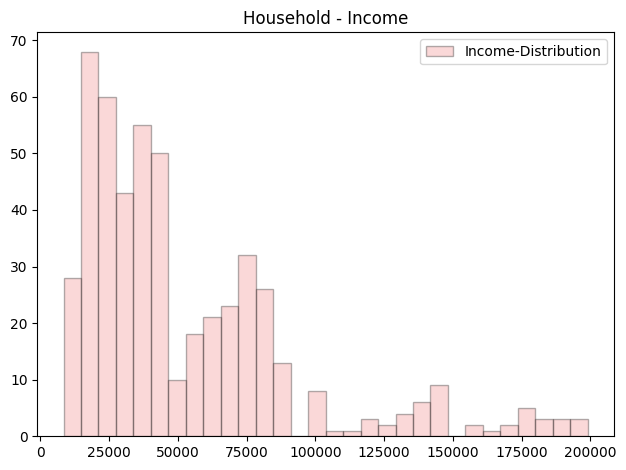

In [94]:
Income = Data["Household_Income"]

plt.hist(Income,bins=30,color="lightcoral",edgecolor="black",alpha=0.3,label="Income-Distribution")
plt.legend(loc="best")
plt.title("Household - Income")
plt.tight_layout()
plt.show()

#### Noraml(Gaussian)-Distribution

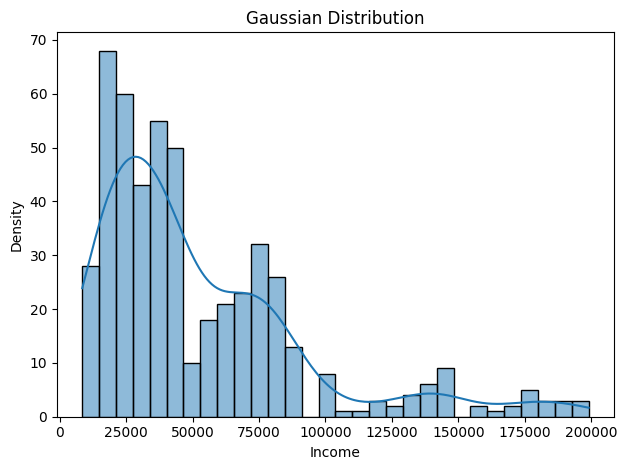

In [95]:
Income = Data["Household_Income"]

plt.figure()
sns.histplot(Income,bins=30,kde=True)
plt.title("Gaussian Distribution")
plt.xlabel("Income")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Skewness

Skewness : 1.6530


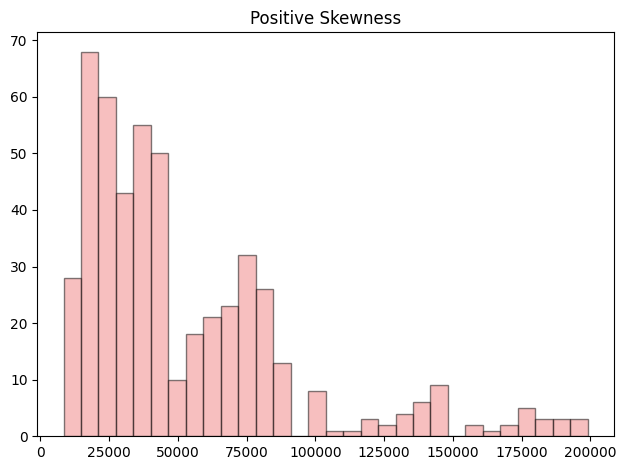

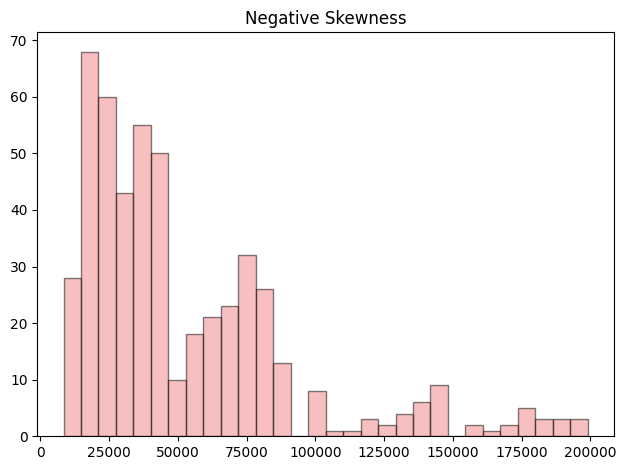

In [96]:
from scipy.stats import skew
Income = Data["Household_Income"]

sk = skew(Income)
print(f"Skewness : {sk:.4f}")

plt.figure()
plt.hist(Income,bins=30,color="lightcoral",edgecolor="black",alpha=0.5)
plt.title("Positive Skewness")
plt.tight_layout()
plt.show()

plt.figure()
plt.hist(Income,bins=30,color="lightcoral",edgecolor="black",alpha=0.5)
plt.title("Negative Skewness")
plt.tight_layout()
plt.show()


#### Kurtosis

kurtosis : 2.6455


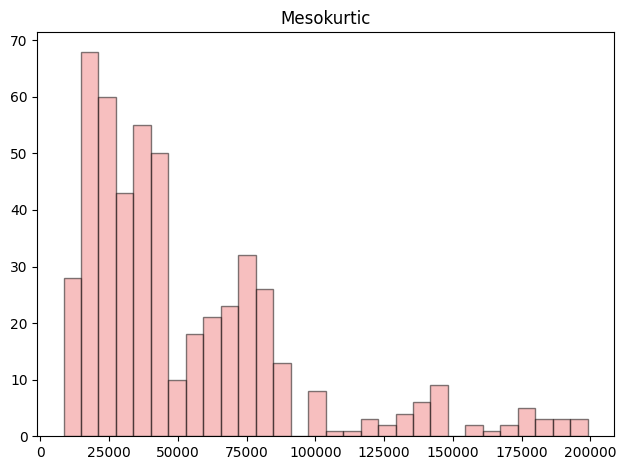

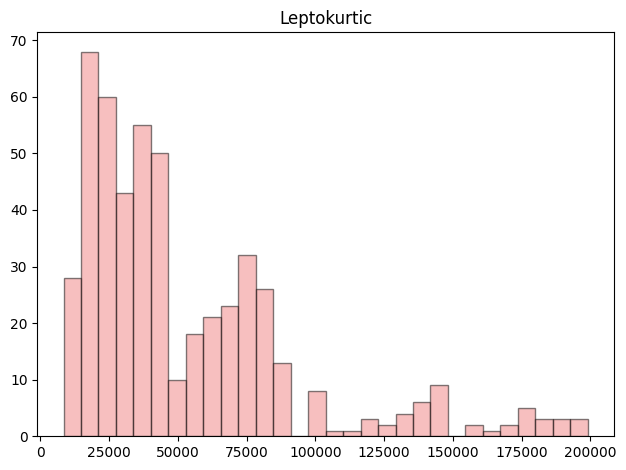

In [97]:
from scipy.stats import kurtosis
Income = Data["Household_Income"]

kt = kurtosis(Income)
print(f"kurtosis : {kt:.4f}")

plt.figure()
plt.hist(Income,bins=30,color="lightcoral",edgecolor="black",alpha=0.5)
plt.title("Mesokurtic")
plt.tight_layout()
plt.show()

plt.figure()
plt.hist(Income,bins=30,color="lightcoral",edgecolor="black",alpha=0.5)
plt.title("Leptokurtic")
plt.tight_layout()
plt.show()

#### Data-Categorization

Income_Group
Middle          221
Upper-Middle    143
Low              89
High             47
Name: count, dtype: int64


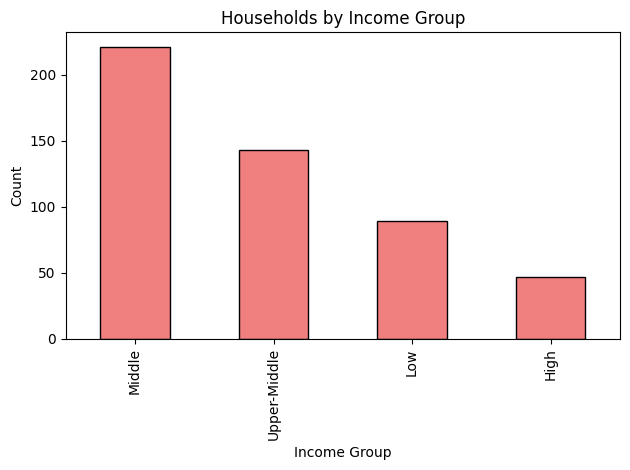

In [98]:
bins = [0,20000,50000,100000,float("inf")]
labels = ["Low","Middle","Upper-Middle","High"]

Data["Income_Group"] = pd.cut(Data["Household_Income"], bins=bins, labels=labels)

print(Data["Income_Group"].value_counts())

Data["Income_Group"].value_counts().plot(kind="bar", color="lightcoral", edgecolor="black")

plt.title("Households by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## Visualization

### Histogram

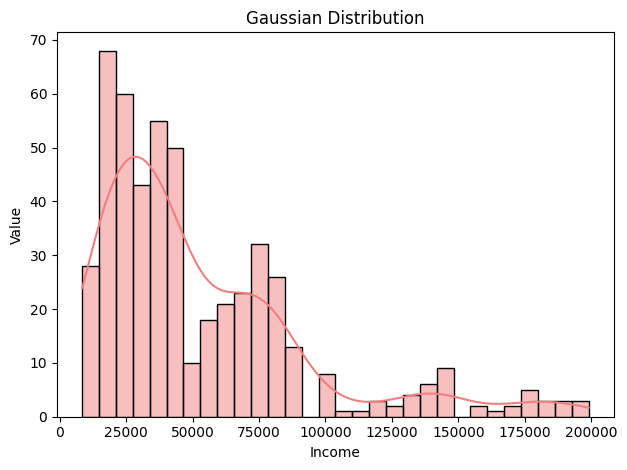

In [99]:
Income = Data["Household_Income"]

plt.figure()
sns.histplot(Income,bins=30,color="lightcoral",kde=True)
plt.title("Gaussian Distribution")
plt.xlabel("Income")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

### Box-plot

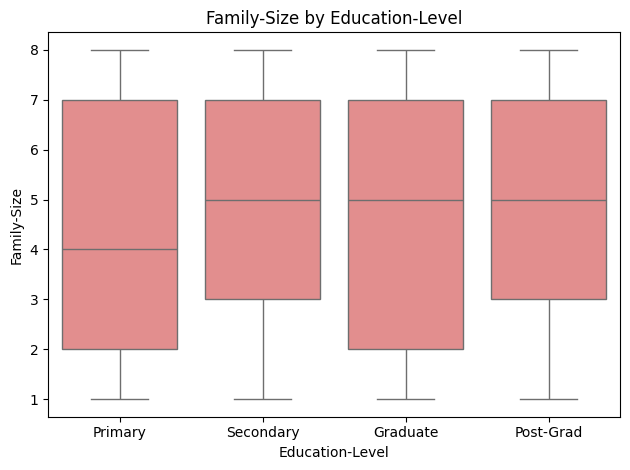

In [100]:
x = Data["Education_Level"]
y = Data["Family_Size"]

plt.figure()
sns.boxplot(x=x,y=y,order=["Primary","Secondary","Graduate","Post-Grad"],color="lightcoral")
plt.title("Family-Size by Education-Level")
plt.xlabel("Education-Level")
plt.ylabel("Family-Size")
plt.tight_layout()
plt.show()


### Distribution Curve Age VS. Income

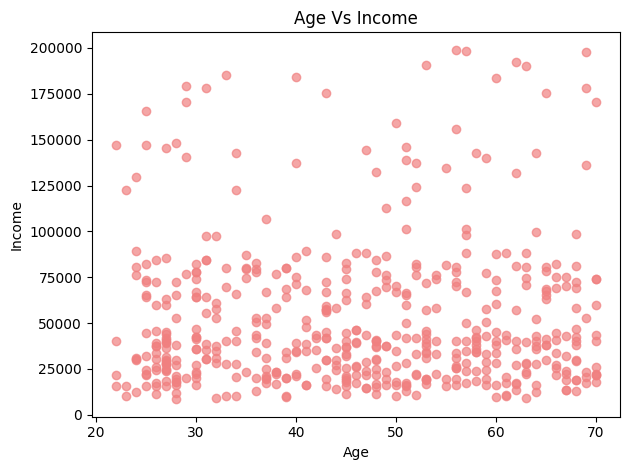

In [101]:
x = Data["Age_of_Household_Head"]
y = Data["Household_Income"]

plt.figure()
plt.scatter(x,y,color="lightcoral",alpha=0.7)
plt.title("Age Vs Income")
plt.xlabel("Age")
plt.ylabel("Income")
plt.tight_layout()
plt.show()